# Analisis Telemetri Lintas Domain & Eksplorasi Data (EDA)
**Dataset:** `data/telemetry_dataset.csv` (4.500 sampel, 40 kolom, 8 skenario eksperimen)  
**Lingkup:** 5G O-RAN Multi-Slice (Radio gNB, Core UPF, & 3GPP NWDAF AnLF)


## Tahap 1: Pemuatan Data & Demarkasi Kolom (Data Ingestion & Demarcation)
- **Tujuan:** Memuat dataset telemetri multi-domain dan memetakan taksonomi kolom sesuai peran fungsional arsitektur sistem.
- **Target:** Dataset 4.500 sampel termuat tanpa error dan 40 kolom terkelompokkan ke dalam 5 grup taksonomi (Metadata, SLA Probe, RAN, Core UPF, dan 3GPP NWDAF).


In [1]:
# 1. Import library analisis dan konfigurasi visualisasi
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 10
plt.rcParams['figure.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['figure.dpi'] = 120

DATASET_PATH = os.path.join('..', 'data', 'telemetry_dataset.csv')
if not os.path.exists(DATASET_PATH):
    DATASET_PATH = os.path.join('data', 'telemetry_dataset.csv')
if not os.path.exists(DATASET_PATH):
    DATASET_PATH = os.path.join('data', 'telemetry_dataset_10min_complete.csv')

df = pd.read_csv(DATASET_PATH)
print(f'Dataset berhasil dimuat dari: {os.path.abspath(DATASET_PATH)}')
print(f'Dimensi Dataset: {df.shape[0]:,} baris x {df.shape[1]} kolom')


Dataset berhasil dimuat dari: d:\Idhul\Program\Thesis\data\telemetry_dataset.csv
Dimensi Dataset: 4,500 baris x 40 kolom


In [2]:
# 2. Pengelompokan taksonomi kolom resmi sesuai Matriks Kapabilitas
METADATA_COLS = [
    'timestamp_utc', 'elapsed_sec', 'run_id', 'scrape_ok', 'scrape_latency_ms',
    'event_phase_id', 'event_scenario', 'event_domain', 'event_component',
    'rapp_diagnosed_bottleneck', 'rapp_confidence'
]

SLA_PROBE_COLS = [
    'e2e_slice1_tput_mbps', 'e2e_slice1_jitter_ms', 'e2e_slice1_rtt_ms', 'e2e_slice1_loss_pct',
    'e2e_slice2_rtt_ms', 'e2e_slice2_loss_pct', 'e2e_probe_freshness'
]

INFRA_RAN_COLS = [
    'ran_prb_cell1', 'ran_prb_cell2', 'ran_mcs_cell1', 'ran_mcs_cell2',
    'ran_bler_cell1', 'ran_bler_cell2', 'ran_snr_cell1', 'ran_snr_cell2'
]

INFRA_CORE_COLS = [
    'estimated_load_embb', 'estimated_load_urllc',
    'upf_backlog_bytes_embb', 'upf_backlog_bytes_urllc',
    'upf_drops_embb', 'upf_drops_urllc'
]

NWDAF_COLS = [
    'nwdaf_load_embb', 'nwdaf_load_urllc', 'nwdaf_comm_ul_bytes', 'nwdaf_comm_dl_bytes',
    'nwdaf_comm_duration_sec', 'nwdaf_comm_vol_std_bytes', 'nwdaf_comm_freshness', 'nwdaf_api_status'
]

classified_total = len(METADATA_COLS) + len(SLA_PROBE_COLS) + len(INFRA_RAN_COLS) + len(INFRA_CORE_COLS) + len(NWDAF_COLS)
print(f'Total Kolom Terklasifikasi: {classified_total} / {df.shape[1]} kolom')


Total Kolom Terklasifikasi: 40 / 40 kolom


## Tahap 2: Pembersihan Data & Audit Kualitas (Data Cleansing & Quality Audit)
- **Tujuan:** Mengaudit kelengkapan data numerik, mendeteksi nilai hilang (`NaN`), mengidentifikasi fitur konstan (varians nol), dan menghitung distribusi kuantitatif SLA (persentil p50, p95, p99 serta rasio pelanggaran).
- **Target:** Tabel audit kualitas 40 kolom, ringkasan integritas 8 run eksperimen dengan jeda waktu nyata antar-run, dan tabel persentil SLA layanan.


In [3]:
# 1. Audit kelengkapan dan variansi per kolom
audit_rows = []
for col in df.columns:
    total_count = len(df[col])
    nan_count = int(df[col].isnull().sum())
    valid_count = total_count - nan_count
    pct_valid = round((valid_count / total_count) * 100.0, 1)
    
    is_numeric = pd.api.types.is_numeric_dtype(df[col])
    num_unique = df[col].nunique(dropna=True)
    is_constant = (num_unique <= 1)
    
    val_min = round(float(df[col].min()), 2) if is_numeric and valid_count > 0 else 'N/A'
    val_max = round(float(df[col].max()), 2) if is_numeric and valid_count > 0 else 'N/A'
    
    audit_rows.append({
        'Kolom': col,
        'Tipe': 'Numeric' if is_numeric else 'String',
        'Valid': valid_count,
        'NaN': nan_count,
        '% Valid': f'{pct_valid}%',
        'Unique': num_unique,
        'Status Variasi': '100% NaN' if valid_count == 0 else ('Konstan' if is_constant else 'Bervariasi'),
        'Min': str(val_min),
        'Max': str(val_max)
    })

df_audit = pd.DataFrame(audit_rows)
pd.set_option('display.max_rows', 45)
display(df_audit)

cols_all_nan = df_audit[df_audit['Status Variasi'] == '100% NaN']['Kolom'].tolist()
cols_constant = df_audit[df_audit['Status Variasi'] == 'Konstan']['Kolom'].tolist()

print(f'Kolom 100% NaN ({len(cols_all_nan)}): {cols_all_nan}')
print(f'Kolom Konstan / Varians Nol ({len(cols_constant)}): {cols_constant}')


,Kolom,Tipe,Valid,NaN,% Valid,Unique,Status Variasi,Min,Max
0,timestamp_utc,String,4500,0,100.0%,4500,Bervariasi,N/A,N/A
1,elapsed_sec,Numeric,4500,0,100.0%,4391,Bervariasi,0.0,599.0
2,run_id,String,4500,0,100.0%,8,Bervariasi,N/A,N/A
3,scrape_ok,Numeric,4500,0,100.0%,1,Konstan,1.0,1.0
4,scrape_latency_ms,Numeric,4500,0,100.0%,1477,Bervariasi,1.57,9.04
5,e2e_slice1_tput_mbps,Numeric,4500,0,100.0%,32,Bervariasi,9.95,81.1
6,e2e_slice1_jitter_ms,Numeric,0,4500,0.0%,0,100% NaN,N/A,N/A
7,e2e_slice1_rtt_ms,Numeric,3300,1200,73.3%,335,Bervariasi,7.08,445.0
8,e2e_slice1_loss_pct,Numeric,4500,0,100.0%,11,Bervariasi,0.0,100.0
9,e2e_slice2_rtt_ms,Numeric,4500,0,100.0%,349,Bervariasi,7.33,139.0


Kolom 100% NaN (3): ['e2e_slice1_jitter_ms', 'nwdaf_load_embb', 'nwdaf_load_urllc']
Kolom Konstan / Varians Nol (11): ['scrape_ok', 'e2e_probe_freshness', 'nwdaf_api_status', 'upf_backlog_bytes_urllc', 'upf_drops_urllc', 'ran_prb_cell2', 'ran_mcs_cell1', 'ran_bler_cell1', 'ran_bler_cell2', 'rapp_diagnosed_bottleneck', 'rapp_confidence']


In [4]:
# 2. Rincian integritas scraping dan jeda waktu fisik antar-run eksperimen
run_summary = []
prev_end_time = None

for run_id, grp in df.groupby('run_id', sort=False):
    scen = grp['event_scenario'].iloc[0]
    dom = grp['event_domain'].iloc[0]
    n_rows = len(grp)
    scrape_ok_pct = round((grp['scrape_ok'].sum() / n_rows) * 100.0, 1)
    
    start_dt = pd.to_datetime(grp['timestamp_utc'].iloc[0])
    end_dt = pd.to_datetime(grp['timestamp_utc'].iloc[-1])
    run_dur = round((end_dt - start_dt).total_seconds(), 1)
    
    if prev_end_time is not None:
        gap_sec = round((start_dt - prev_end_time).total_seconds(), 1)
        gap_str = f'{int(gap_sec // 60)}m {int(gap_sec % 60)}s ({gap_sec}s)'
    else:
        gap_str = 'Start Run'
    prev_end_time = end_dt
    
    prb_c1_mean = round(float(grp['ran_prb_cell1'].mean()), 1)
    backlog_max = int(grp['upf_backlog_bytes_embb'].max())
    nwdaf_status = int(grp['nwdaf_api_status'].mean())
    nwdaf_valid_rows = int(grp['nwdaf_comm_ul_bytes'].notnull().sum())
    
    run_summary.append({
        'Run ID': run_id,
        'Skenario': scen,
        'Domain': dom,
        'Sampel': n_rows,
        'Durasi (s)': run_dur,
        'Jeda Pra-Run': gap_str,
        'Scrape OK': f'{scrape_ok_pct}%',
        'PRB C1 Avg (%)': f'{prb_c1_mean}%',
        'Backlog Max (B)': f'{backlog_max:,}',
        'NWDAF Status': nwdaf_status,
        'NWDAF Valid': f'{nwdaf_valid_rows}/{n_rows}'
    })

df_run_summary = pd.DataFrame(run_summary)
display(df_run_summary)


,Run ID,Skenario,Domain,Sampel,Durasi (s),Jeda Pra-Run,Scrape OK,PRB C1 Avg (%),Backlog Max (B),NWDAF Status,NWDAF Valid
0,EXP_S1_20261019_232208,S1_NORMAL_LIGHT,BASELINE,600,599.0,Start Run,100.0%,63.0%,0,1,599/600
1,EXP_S2_20261019_234048,S2_NORMAL_HIGH,BASELINE,600,599.0,8m 41s (521.4s),100.0%,74.1%,0,1,599/600
2,EXP_S3_20261019_235917,S3_RAN_OVERLOAD,RAN,600,599.0,8m 30s (510.4s),100.0%,100.0%,0,1,599/600
3,EXP_S6_20261020_001105,S6_CORE_QUEUE_TBF,CORE,600,599.0,1m 48s (108.4s),100.0%,74.6%,"310,234",1,598/600
4,EXP_S9_20261020_084020,S9_JOINT_OVERLOAD,JOINT,600,599.0,499m 15s (29955.7s),100.0%,100.0%,"310,226",1,598/600
5,EXP_S10_A_20261020_091150,S10_A_RELEASE_RAN,CORE,600,599.0,21m 31s (1291.6s),100.0%,72.7%,"310,218",1,599/600
6,EXP_S10_B_20261020_092453,S10_B_RELEASE_CORE,BASELINE,600,599.0,3m 3s (183.7s),100.0%,74.7%,0,1,599/600
7,EXP_CLEAR_20261020_093812,CLEAR_FAULT,BASELINE,300,299.0,3m 20s (200.1s),100.0%,57.8%,0,1,298/300


In [5]:
# 3. Distribusi kuantitatif metrik SLA: Persentil RTT, Loss, dan Rasio Pelanggaran Ambang
sla_rows = []
for run_id, grp in df.groupby('run_id', sort=False):
    scen = grp['event_scenario'].iloc[0]
    n_total = len(grp)
    
    s1_rtt = grp['e2e_slice1_rtt_ms']
    s1_nan_count = int(s1_rtt.isnull().sum())
    s1_outage_pct = round((s1_nan_count / n_total) * 100.0, 1)
    s1_p50 = round(float(s1_rtt.quantile(0.50)), 2) if (n_total - s1_nan_count) > 0 else 'N/A'
    s1_p95 = round(float(s1_rtt.quantile(0.95)), 2) if (n_total - s1_nan_count) > 0 else 'N/A'
    s1_p99 = round(float(s1_rtt.quantile(0.99)), 2) if (n_total - s1_nan_count) > 0 else 'N/A'
    s1_loss_mean = round(float(grp['e2e_slice1_loss_pct'].mean()), 1)
    
    s2_rtt = grp['e2e_slice2_rtt_ms']
    s2_p50 = round(float(s2_rtt.quantile(0.50)), 2)
    s2_p95 = round(float(s2_rtt.quantile(0.95)), 2)
    s2_p99 = round(float(s2_rtt.quantile(0.99)), 2)
    s2_loss_mean = round(float(grp['e2e_slice2_loss_pct'].mean()), 1)
    s2_viol_count = int((s2_rtt > 20.0).sum())
    s2_viol_pct = round((s2_viol_count / n_total) * 100.0, 1)
    
    sla_rows.append({
        'Skenario': scen,
        'eMBB Outage (%)': f'{s1_outage_pct}%',
        'eMBB Loss (%)': f'{s1_loss_mean}%',
        'eMBB RTT p50 (ms)': s1_p50,
        'eMBB RTT p95 (ms)': s1_p95,
        'eMBB RTT p99 (ms)': s1_p99,
        'URLLC Loss (%)': f'{s2_loss_mean}%',
        'URLLC RTT p50 (ms)': s2_p50,
        'URLLC RTT p95 (ms)': s2_p95,
        'URLLC RTT p99 (ms)': s2_p99,
        'URLLC >20ms Viol (%)': f'{s2_viol_pct}%'
    })

df_sla_dist = pd.DataFrame(sla_rows)
display(df_sla_dist)


,Skenario,eMBB Outage (%),eMBB Loss (%),eMBB RTT p50 (ms),eMBB RTT p95 (ms),eMBB RTT p99 (ms),URLLC Loss (%),URLLC RTT p50 (ms),URLLC RTT p95 (ms),URLLC RTT p99 (ms),URLLC >20ms Viol (%)
0,S1_NORMAL_LIGHT,0.0%,0.0%,18.5,31.5,35.2,0.0%,21.60,26.60,30.11,74.2%
1,S2_NORMAL_HIGH,0.0%,0.0%,17.7,29.91,33.91,0.0%,23.00,28.10,29.70,85.2%
2,S3_RAN_OVERLOAD,100.0%,100.0%,N/A,N/A,N/A,5.6%,26.30,48.41,121.04,98.0%
3,S6_CORE_QUEUE_TBF,0.0%,20.1%,425.0,433.0,436.0,0.0%,22.70,27.70,31.70,84.5%
4,S9_JOINT_OVERLOAD,100.0%,100.0%,N/A,N/A,N/A,6.0%,26.05,52.42,127.00,96.8%
5,S10_A_RELEASE_RAN,0.0%,20.5%,425.0,433.0,437.01,0.0%,22.90,28.20,29.90,84.8%
6,S10_B_RELEASE_CORE,0.0%,0.0%,17.7,28.1,33.8,0.0%,22.95,27.90,31.11,87.0%
7,CLEAR_FAULT,0.0%,0.0%,17.9,31.91,35.61,0.0%,21.70,26.80,28.91,73.3%


## Tahap 3: Pra-pemrosesan Data & Rekayasa Fitur (Data Preprocessing & Feature Engineering)
- **Tujuan:** Menghitung fitur turunan fisik, memetakan distribusi kelas target, dan mendemarkasi set fitur masukan secara ketat ke dalam 3 protokol studi ablasi (Set A: RAN-Only, Set B: RAN + NWDAF AnLF, Set C: RAN + Kernel Reference) sesuai Matriks Kapabilitas.
- **Target:** Variabel turunan terhitung (`upf_backlog_kb`), distribusi frekuensi kelas target `event_domain`, dan penetapan resmi 3 set fitur masukan untuk evaluasi komparatif.


In [6]:
# 1. Perhitungan fitur turunan
df['upf_backlog_kb'] = df['upf_backlog_bytes_embb'] / 1024.0
df['ran_prb_pct'] = df['ran_prb_cell1'].clip(0.0, 100.0)

# 2. Distribusi frekuensi kelas target domain
target_dist = df['event_domain'].value_counts()
target_pct = df['event_domain'].value_counts(normalize=True) * 100.0
df_class_dist = pd.DataFrame({
    'Jumlah Sampel': target_dist,
    'Proporsi (%)': target_pct.round(2)
})
print('=== DISTRIBUSI KELAS TARGET (event_domain) ===')
display(df_class_dist)

# 3. Demarkasi Tiga Set Fitur Masukan Resmi (Protokol Studi Ablasi Tesis)
FEATURE_SET_A_RAN = [
    'ran_prb_cell1', 'ran_snr_cell1'
]

FEATURE_SET_B_NWDAF = [
    'ran_prb_cell1', 'ran_snr_cell1',
    'nwdaf_comm_ul_bytes', 'nwdaf_comm_vol_std_bytes', 'nwdaf_comm_duration_sec'
]

FEATURE_SET_C_KERNEL_REF = [
    'ran_prb_cell1', 'ran_snr_cell1',
    'upf_backlog_bytes_embb', 'upf_drops_embb', 'estimated_load_embb'
]

print(f'Set A (RAN-Only Baseline): {len(FEATURE_SET_A_RAN)} fitur ->', FEATURE_SET_A_RAN)
print(f'Set B (RAN + 3GPP NWDAF AnLF - Eksperimen Utama): {len(FEATURE_SET_B_NWDAF)} fitur ->', FEATURE_SET_B_NWDAF)
print(f'Set C (RAN + Kernel Host OAM - Referensi Pembanding): {len(FEATURE_SET_C_KERNEL_REF)} fitur ->', FEATURE_SET_C_KERNEL_REF)


=== DISTRIBUSI KELAS TARGET (event_domain) ===


,Jumlah Sampel,Proporsi (%)
event_domain,,
BASELINE,2100,46.67
CORE,1200,26.67
RAN,600,13.33
JOINT,600,13.33


Set A (RAN-Only Baseline): 2 fitur -> ['ran_prb_cell1', 'ran_snr_cell1']
Set B (RAN + 3GPP NWDAF AnLF - Eksperimen Utama): 5 fitur -> ['ran_prb_cell1', 'ran_snr_cell1', 'nwdaf_comm_ul_bytes', 'nwdaf_comm_vol_std_bytes', 'nwdaf_comm_duration_sec']
Set C (RAN + Kernel Host OAM - Referensi Pembanding): 5 fitur -> ['ran_prb_cell1', 'ran_snr_cell1', 'upf_backlog_bytes_embb', 'upf_drops_embb', 'estimated_load_embb']


## Tahap 4: Analisis Data Eksploratif (Exploratory Data Analysis / EDA)
- **Tujuan:** Menampilkan visualisasi runtun waktu lintas run dengan garis terputus pada jeda nyata, menganalisis dinamika tangga telemetri 3GPP NWDAF AnLF, mengevaluasi kondisi pasangan terkendali (S2 vs S6 serta perbandingan kondisi antar-run S9 -> S10_A -> S10_B), dan menghitung matriks korelasi beserta jumlah pasangan observasi valid.
- **Target:** Plot runtun waktu multi-panel bersekat jeda fisik, plot tangga berkala NWDAF, boxplot pasangan terkendali, dan heatmap korelasi Spearman yang teranotasi jumlah sampel valid ($N$).


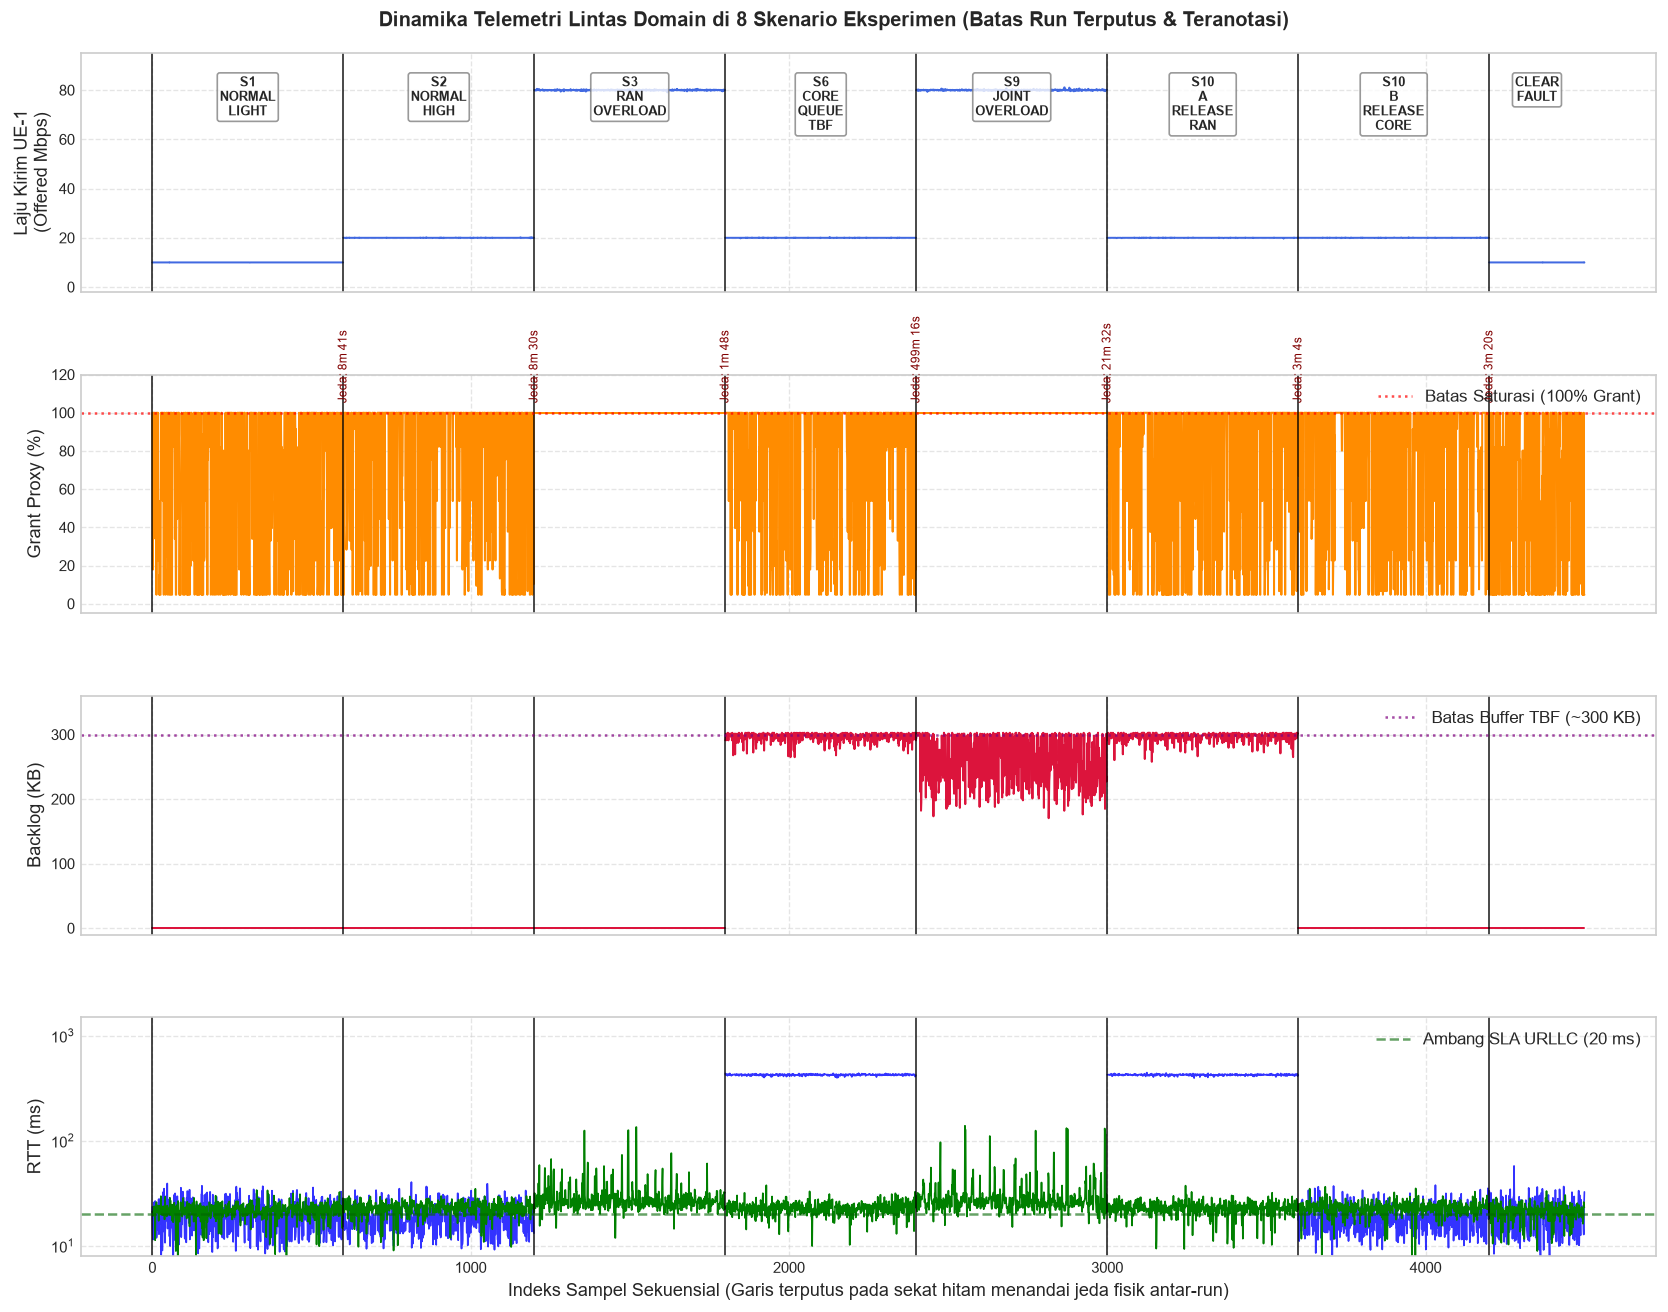

In [7]:
# 1. Dinamika runtun waktu multi-panel (Garis terputus pada jeda fisik antar-run)
fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)

current_idx = 0
prev_end_dt = None

for run_id, grp in df.groupby('run_id', sort=False):
    scen = grp['event_scenario'].iloc[0]
    start_dt = pd.to_datetime(grp['timestamp_utc'].iloc[0])
    end_dt = pd.to_datetime(grp['timestamp_utc'].iloc[-1])
    n_rows = len(grp)
    x_run = np.arange(current_idx, current_idx + n_rows)
    
    # Throughput laju pengiriman UE-1
    axes[0].plot(x_run, grp['e2e_slice1_tput_mbps'], color='royalblue', lw=1.2)
    
    # Proxy Alokasi Grant PUSCH Cell-1
    axes[1].plot(x_run, grp['ran_prb_cell1'], color='darkorange', lw=1.2)
    
    # Kedalaman Antrean UPF (Backlog KB)
    axes[2].plot(x_run, grp['upf_backlog_kb'], color='crimson', lw=1.2)
    
    # Latensi Canary RTT UE-1 & UE-2
    axes[3].plot(x_run, grp['e2e_slice1_rtt_ms'], color='blue', lw=1.0, alpha=0.8)
    axes[3].plot(x_run, grp['e2e_slice2_rtt_ms'], color='green', lw=1.0)
    
    # Garis sekat antar-run
    for ax in axes:
        ax.axvline(current_idx, color='black', ls='-', lw=1.2, alpha=0.7)
    
    # Label skenario dan jeda waktu
    mid_point = current_idx + n_rows / 2
    label_clean = scen.replace('_', '\n')
    axes[0].text(mid_point, 86, label_clean, ha='center', va='top', fontsize=7.5, fontweight='bold',
                 bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='gray'))
    
    if prev_end_dt is not None:
        gap_sec = round((start_dt - prev_end_dt).total_seconds(), 0)
        gap_label = f'Jeda: {int(gap_sec // 60)}m {int(gap_sec % 60)}s'
        axes[1].text(current_idx, 105, gap_label, ha='center', va='bottom', fontsize=7, color='maroon', rotation=90)
    
    prev_end_dt = end_dt
    current_idx += n_rows

# Konfigurasi Sumbu & Label
axes[0].set_ylabel('Laju Kirim UE-1\n(Offered Mbps)')
axes[0].set_ylim(-2, 95)
axes[0].grid(True, ls='--', alpha=0.5)

axes[1].axhline(100.0, color='red', ls=':', alpha=0.7, label='Batas Saturasi (100% Grant)')
axes[1].set_ylabel('Grant Proxy (%)')
axes[1].set_ylim(-5, 120)
axes[1].grid(True, ls='--', alpha=0.5)
axes[1].legend(loc='upper right')

axes[2].axhline(300.0, color='purple', ls=':', alpha=0.7, label='Batas Buffer TBF (~300 KB)')
axes[2].set_ylabel('Backlog (KB)')
axes[2].set_ylim(-10, 360)
axes[2].grid(True, ls='--', alpha=0.5)
axes[2].legend(loc='upper right')

axes[3].axhline(20.0, color='darkgreen', ls='--', alpha=0.6, label='Ambang SLA URLLC (20 ms)')
axes[3].set_ylabel('RTT (ms)')
axes[3].set_yscale('log')
axes[3].set_ylim(8, 1500)
axes[3].grid(True, ls='--', alpha=0.5)
axes[3].legend(loc='upper right')

axes[3].set_xlabel('Indeks Sampel Sekuensial (Garis terputus pada sekat hitam menandai jeda fisik antar-run)')
plt.suptitle('Dinamika Telemetri Lintas Domain di 8 Skenario Eksperimen (Batas Run Terputus & Teranotasi)', y=0.99, fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


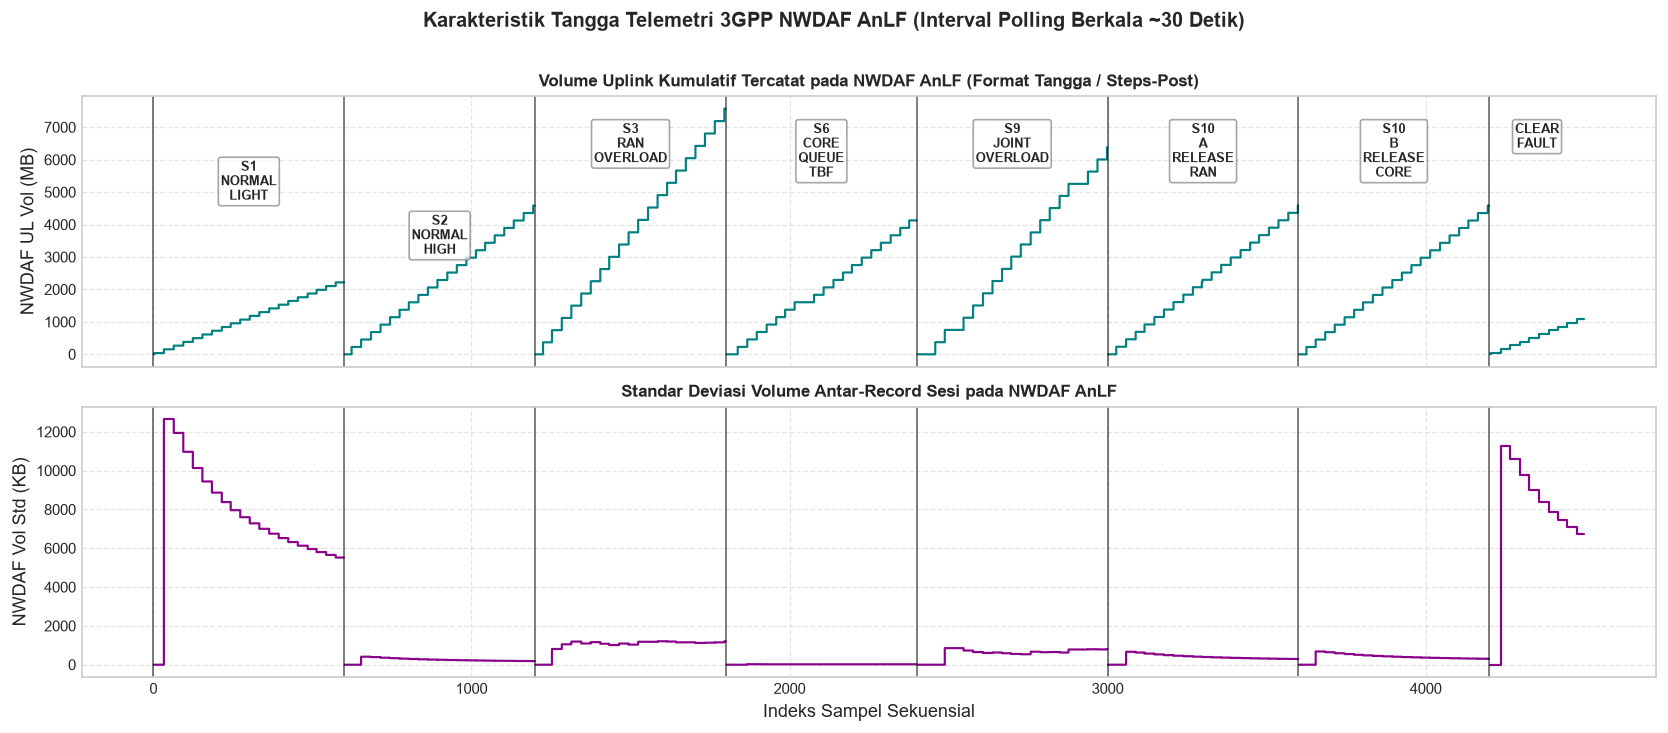

In [8]:
# 2. Dinamika tangga telemetri 3GPP NWDAF AnLF (Karakteristik polling berkala ~30 detik)
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

current_idx = 0
for run_id, grp in df.groupby('run_id', sort=False):
    scen = grp['event_scenario'].iloc[0]
    n_rows = len(grp)
    x_run = np.arange(current_idx, current_idx + n_rows)
    
    # Volume Uplink (MB) via step plot
    axes[0].plot(x_run, grp['nwdaf_comm_ul_bytes'] / 1e6, color='teal', lw=1.3, drawstyle='steps-post')
    
    # Standar Deviasi Volume (KB) via step plot
    axes[1].plot(x_run, grp['nwdaf_comm_vol_std_bytes'] / 1e3, color='darkmagenta', lw=1.3, drawstyle='steps-post')
    
    for ax in axes:
        ax.axvline(current_idx, color='black', ls='-', lw=1.0, alpha=0.6)
    
    mid_point = current_idx + n_rows / 2
    label_clean = scen.replace('_', '\n')
    axes[0].text(mid_point, axes[0].get_ylim()[1] * 0.9 if current_idx > 0 else 6000, label_clean,
                 ha='center', va='top', fontsize=7.5, fontweight='bold',
                 bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7, edgecolor='gray'))
    current_idx += n_rows

axes[0].set_ylabel('NWDAF UL Vol (MB)')
axes[0].grid(True, ls='--', alpha=0.5)
axes[0].set_title('Volume Uplink Kumulatif Tercatat pada NWDAF AnLF (Format Tangga / Steps-Post)', fontsize=10, fontweight='bold')

axes[1].set_ylabel('NWDAF Vol Std (KB)')
axes[1].grid(True, ls='--', alpha=0.5)
axes[1].set_title('Standar Deviasi Volume Antar-Record Sesi pada NWDAF AnLF', fontsize=10, fontweight='bold')
axes[1].set_xlabel('Indeks Sampel Sekuensial')

plt.suptitle('Karakteristik Tangga Telemetri 3GPP NWDAF AnLF (Interval Polling Berkala ~30 Detik)', y=1.01, fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


C:\Users\idhul\AppData\Local\Temp\ipykernel_26356\1125603544.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_s2_s6, x='event_scenario', y='e2e_slice1_rtt_ms', ax=axes[0], palette=['lightblue', 'salmon'])
C:\Users\idhul\AppData\Local\Temp\ipykernel_26356\1125603544.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['S2 (Tanpa TC)', 'S6 (TBF 12M)'])
C:\Users\idhul\AppData\Local\Temp\ipykernel_26356\1125603544.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_s2_s6, x='event_scenario', y='upf_backlog_bytes_embb', ax=axes[1], p

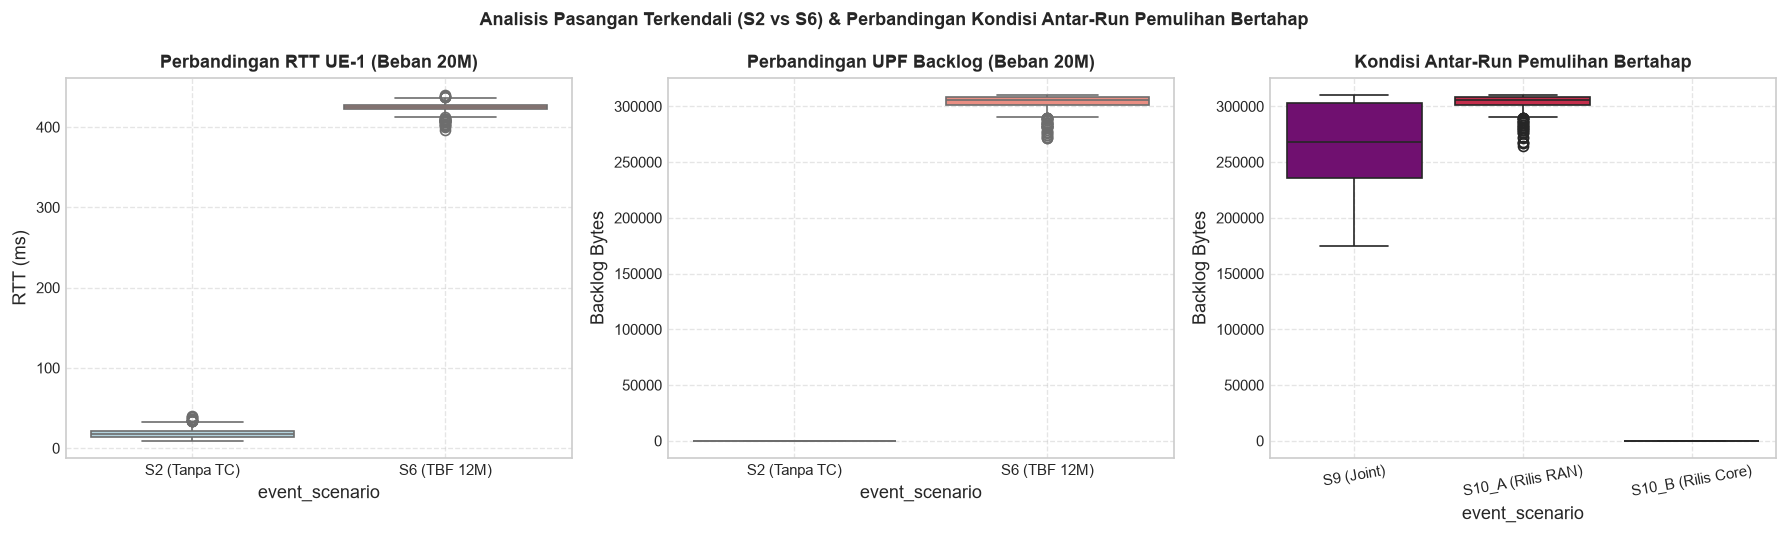

In [9]:
# 3. Evaluasi pasangan terkendali: S2 vs S6 dan Perbandingan Kondisi Antar-Run Pemulihan Bertahap
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# A. Perbandingan RTT UE-1 pada S2 vs S6
df_s2_s6 = df[df['event_scenario'].isin(['S2_NORMAL_HIGH', 'S6_CORE_QUEUE_TBF'])].copy()
sns.boxplot(data=df_s2_s6, x='event_scenario', y='e2e_slice1_rtt_ms', ax=axes[0], palette=['lightblue', 'salmon'])
axes[0].set_title('Perbandingan RTT UE-1 (Beban 20M)', fontweight='bold')
axes[0].set_ylabel('RTT (ms)')
axes[0].set_xticklabels(['S2 (Tanpa TC)', 'S6 (TBF 12M)'])
axes[0].grid(True, ls='--', alpha=0.5)

# B. Perbandingan UPF Backlog pada S2 vs S6
sns.boxplot(data=df_s2_s6, x='event_scenario', y='upf_backlog_bytes_embb', ax=axes[1], palette=['lightblue', 'salmon'])
axes[1].set_title('Perbandingan UPF Backlog (Beban 20M)', fontweight='bold')
axes[1].set_ylabel('Backlog Bytes')
axes[1].set_xticklabels(['S2 (Tanpa TC)', 'S6 (TBF 12M)'])
axes[1].grid(True, ls='--', alpha=0.5)

# C. Perbandingan Kondisi Antar-Run Pemulihan Bertahap: S9 -> S10_A -> S10_B
df_rec = df[df['event_scenario'].isin(['S9_JOINT_OVERLOAD', 'S10_A_RELEASE_RAN', 'S10_B_RELEASE_CORE'])].copy()
rec_order = ['S9_JOINT_OVERLOAD', 'S10_A_RELEASE_RAN', 'S10_B_RELEASE_CORE']
sns.boxplot(data=df_rec, x='event_scenario', y='upf_backlog_bytes_embb', order=rec_order, ax=axes[2], palette=['purple', 'crimson', 'lightgreen'])
axes[2].set_title('Kondisi Antar-Run Pemulihan Bertahap', fontweight='bold')
axes[2].set_ylabel('Backlog Bytes')
axes[2].set_xticklabels(['S9 (Joint)', 'S10_A (Rilis RAN)', 'S10_B (Rilis Core)'], rotation=10)
axes[2].grid(True, ls='--', alpha=0.5)

plt.suptitle('Analisis Pasangan Terkendali (S2 vs S6) & Perbandingan Kondisi Antar-Run Pemulihan Bertahap', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()


=== JUMLAH PASANGAN OBSERVASI VALID (PAIRWISE COMPLETE N) ===


,e2e_slice1_tput_mbps,e2e_slice1_loss_pct,e2e_slice1_rtt_ms,e2e_slice2_rtt_ms,e2e_slice2_loss_pct,ran_prb_cell1,ran_snr_cell1,upf_backlog_bytes_embb,upf_drops_embb,estimated_load_embb,nwdaf_comm_ul_bytes,nwdaf_comm_vol_std_bytes
e2e_slice1_tput_mbps,4500,4500,3300,4500,4500,4500,4500,4500,4500,4500,4489,4489
e2e_slice1_loss_pct,4500,4500,3300,4500,4500,4500,4500,4500,4500,4500,4489,4489
e2e_slice1_rtt_ms,3300,3300,3300,3300,3300,3300,3300,3300,3300,3300,3292,3292
e2e_slice2_rtt_ms,4500,4500,3300,4500,4500,4500,4500,4500,4500,4500,4489,4489
e2e_slice2_loss_pct,4500,4500,3300,4500,4500,4500,4500,4500,4500,4500,4489,4489
ran_prb_cell1,4500,4500,3300,4500,4500,4500,4500,4500,4500,4500,4489,4489
ran_snr_cell1,4500,4500,3300,4500,4500,4500,4500,4500,4500,4500,4489,4489
upf_backlog_bytes_embb,4500,4500,3300,4500,4500,4500,4500,4500,4500,4500,4489,4489
upf_drops_embb,4500,4500,3300,4500,4500,4500,4500,4500,4500,4500,4489,4489
estimated_load_embb,4500,4500,3300,4500,4500,4500,4500,4500,4500,4500,4489,4489


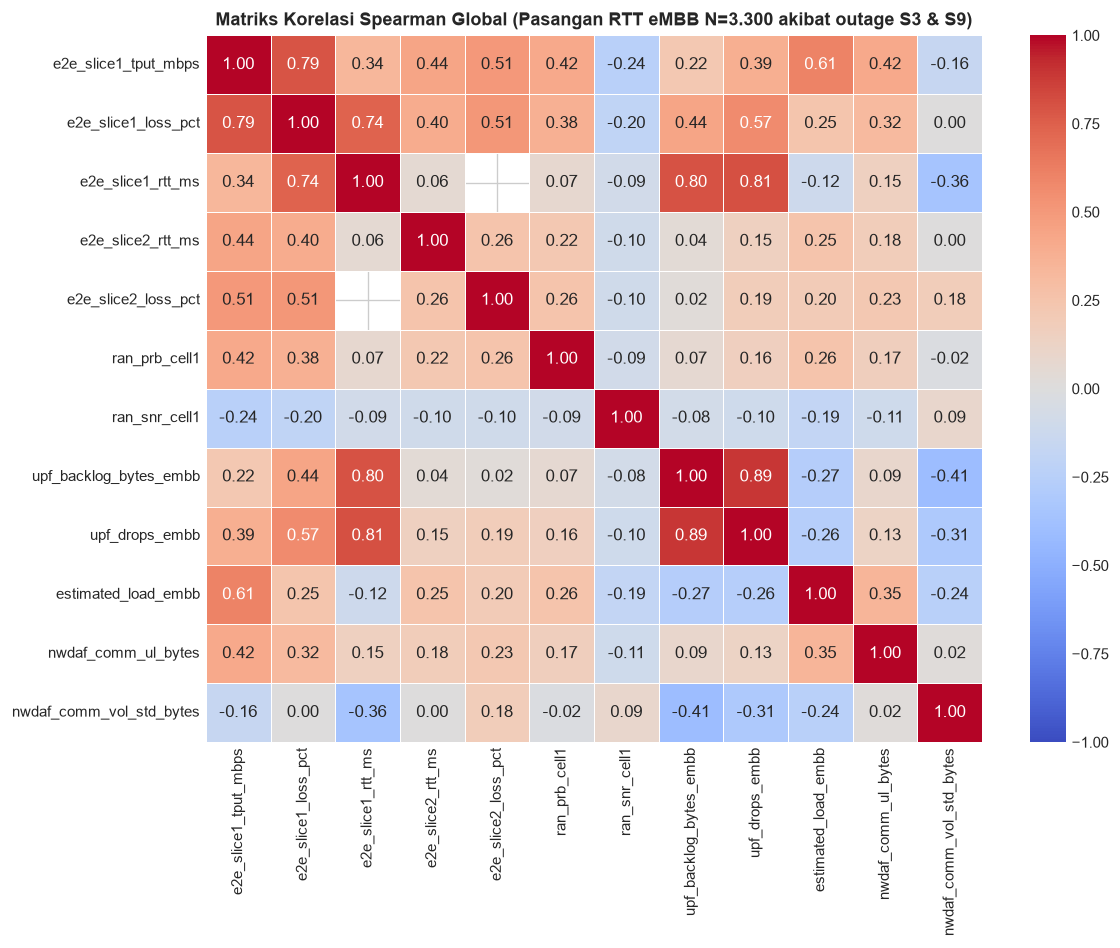

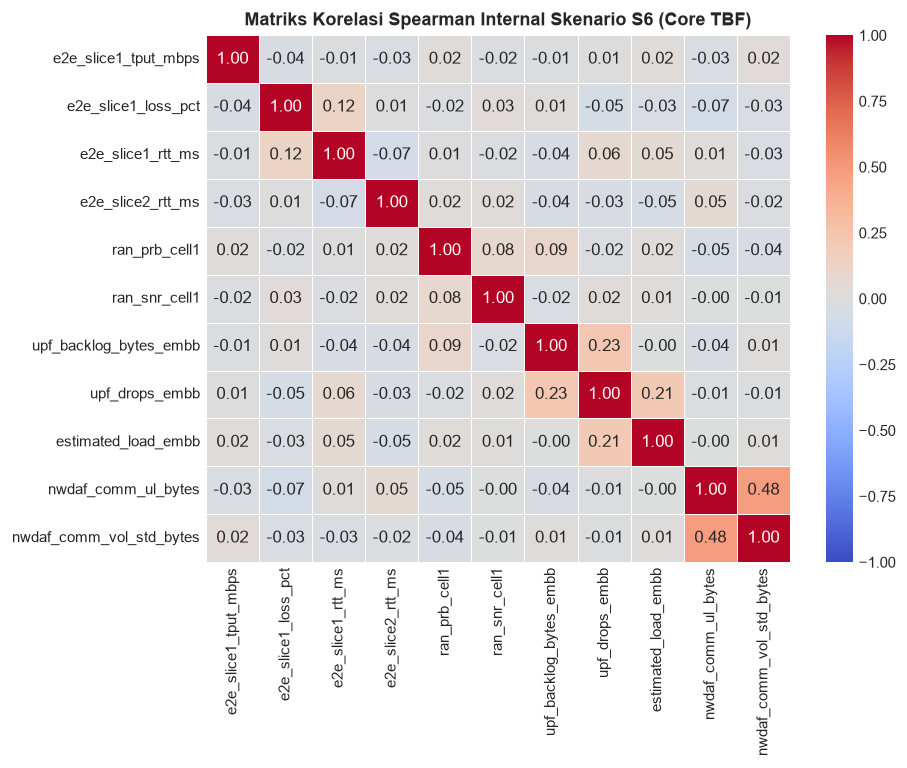

In [10]:
# 4. Matriks korelasi Spearman dan audit jumlah pasangan observasi berpasangan (N)
candidate_features = [
    'e2e_slice1_tput_mbps', 'e2e_slice1_loss_pct', 'e2e_slice1_rtt_ms',
    'e2e_slice2_rtt_ms', 'e2e_slice2_loss_pct',
    'ran_prb_cell1', 'ran_snr_cell1',
    'upf_backlog_bytes_embb', 'upf_drops_embb', 'estimated_load_embb',
    'nwdaf_comm_ul_bytes', 'nwdaf_comm_vol_std_bytes'
]

# Hitung matriks jumlah observasi berpasangan valid (N)
n_matrix = pd.DataFrame(index=candidate_features, columns=candidate_features)
for col1 in candidate_features:
    for col2 in candidate_features:
        n_matrix.loc[col1, col2] = int(df[[col1, col2]].dropna().shape[0])

print('=== JUMLAH PASANGAN OBSERVASI VALID (PAIRWISE COMPLETE N) ===')
display(n_matrix)

# Korelasi Spearman Global
corr_global = df[candidate_features].corr(method='spearman')
plt.figure(figsize=(10, 8))
sns.heatmap(corr_global, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1.0, vmax=1.0, linewidths=0.5)
plt.title('Matriks Korelasi Spearman Global (Pasangan RTT eMBB N=3.300 akibat outage S3 & S9)', fontweight='bold')
plt.tight_layout()
plt.show()

# Korelasi Spearman Internal Skenario Core Bottleneck (S6)
df_s6 = df[df['event_scenario'] == 'S6_CORE_QUEUE_TBF'][candidate_features].dropna(axis=1, how='all')
varying_s6 = [c for c in df_s6.columns if df_s6[c].nunique() > 1]
corr_s6 = df_s6[varying_s6].corr(method='spearman')
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr_s6, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1.0, vmax=1.0, linewidths=0.5)
plt.title('Matriks Korelasi Spearman Internal Skenario S6 (Core TBF)', fontweight='bold')
plt.tight_layout()
plt.show()


## Tahap 5: Evaluasi Distribusi & Keterpisahan Data per Domain (Feature Separability Assessment)
- **Tujuan:** Menampilkan visualisasi distribusi dan matriks statistik deskriptif fitur fisik pada masing-masing label domain target.
- **Target:** Boxplot komparatif dan tabel agregasi statistik deskriptif kuantitatif (`count`, `mean`, `std`, `median`, `min`, `max`) per domain target.


C:\Users\idhul\AppData\Local\Temp\ipykernel_26356\2904806707.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='event_domain', y='ran_prb_cell1', order=domain_order, ax=axes[0], palette=palette)
C:\Users\idhul\AppData\Local\Temp\ipykernel_26356\2904806707.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='event_domain', y='upf_backlog_bytes_embb', order=domain_order, ax=axes[1], palette=palette)


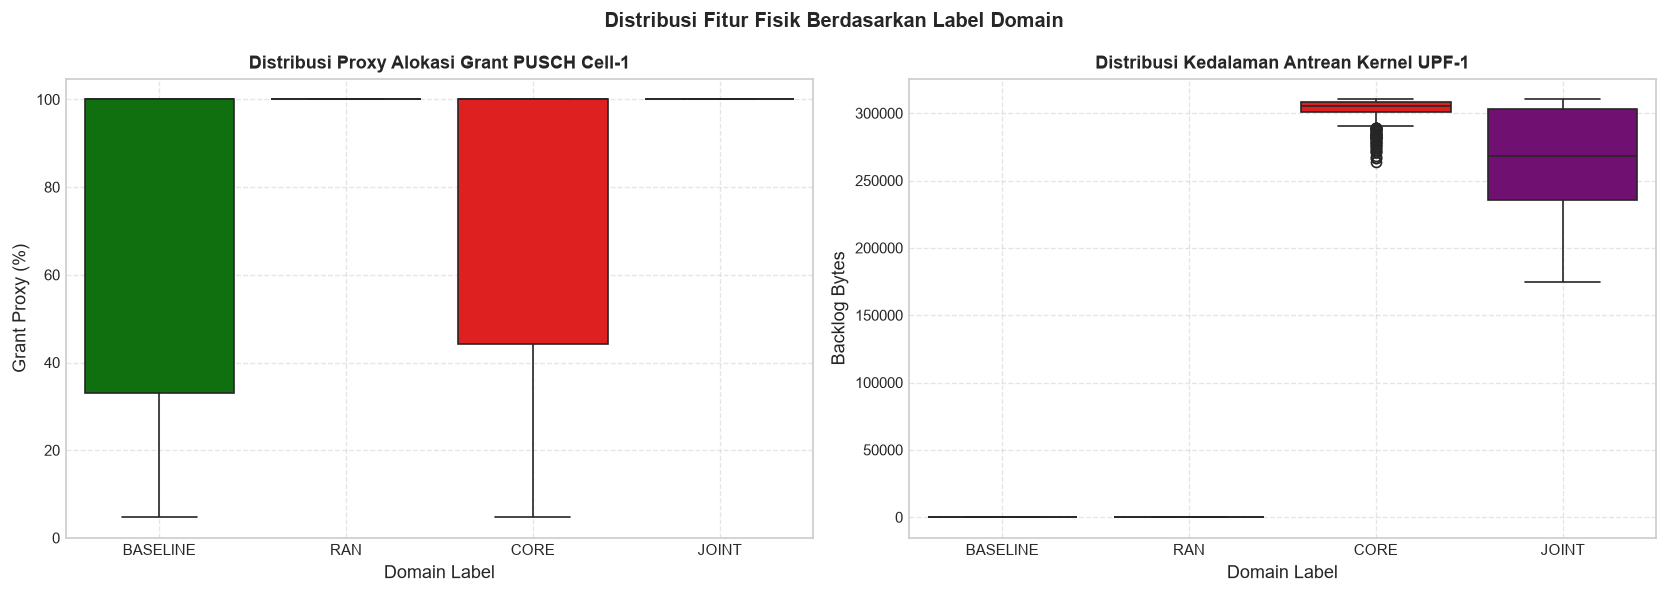

=== STATISTIK DESKRIPTIF FITUR FISIK PER DOMAIN TARGET ===


ran_prb_cell1                                       \
                     count    mean    std median     min    max   
event_domain                                                      
BASELINE              2100   68.78  38.56  100.0    4.72  100.0   
CORE                  1200   73.64  37.59  100.0    4.72  100.0   
JOINT                  600  100.00   0.00  100.0  100.00  100.0   
RAN                    600  100.00   0.00  100.0  100.00  100.0   

             upf_backlog_bytes_embb                                           \
                              count       mean       std    median       min   
event_domain                                                                   
BASELINE                       2100       0.00      0.00       0.0       0.0   
CORE                           1200  303692.67   6983.76  305690.0  264036.0   
JOINT                           600  265590.06  36113.64  268357.0  174570.0   
RAN                             600       0.00      0.00       0.0       0.0   

                       nwdaf_comm_ul_bytes                              \
                   max               count          mean           std   
event_domain                                                             
BASELINE           0.0                2095  1.670163e+09  1.259472e+09   
CORE          310234.0                1197  2.103617e+09  1.278680e+09   
JOINT         310226.0                 598  2.890415e+09  1.953256e+09   
RAN                0.0                 599  3.660936e+09  2.187210e+09   

                                               
                    median  min           max  
event_domain                                   
BASELINE      1.373935e+09  0.0  4.585925e+09  
CORE          2.064418e+09  0.0  4.592382e+09  
JOINT         3.012183e+09  0.0  6.380446e+09  
RAN           3.762535e+09  0.0  7.575908e+09

In [11]:
# 1. Visualisasi distribusi fitur fisik per label domain
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
domain_order = ['BASELINE', 'RAN', 'CORE', 'JOINT']
palette = {'BASELINE': 'green', 'RAN': 'orange', 'CORE': 'red', 'JOINT': 'purple'}

# Distribusi PRB C1 per Domain
sns.boxplot(data=df, x='event_domain', y='ran_prb_cell1', order=domain_order, ax=axes[0], palette=palette)
axes[0].set_title('Distribusi Proxy Alokasi Grant PUSCH Cell-1', fontweight='bold')
axes[0].set_xlabel('Domain Label')
axes[0].set_ylabel('Grant Proxy (%)')
axes[0].grid(True, ls='--', alpha=0.5)

# Distribusi UPF Backlog per Domain
sns.boxplot(data=df, x='event_domain', y='upf_backlog_bytes_embb', order=domain_order, ax=axes[1], palette=palette)
axes[1].set_title('Distribusi Kedalaman Antrean Kernel UPF-1', fontweight='bold')
axes[1].set_xlabel('Domain Label')
axes[1].set_ylabel('Backlog Bytes')
axes[1].grid(True, ls='--', alpha=0.5)

plt.suptitle('Distribusi Fitur Fisik Berdasarkan Label Domain', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Tabel statistik deskriptif kuantitatif per domain target
features_eval = ['ran_prb_cell1', 'upf_backlog_bytes_embb', 'nwdaf_comm_ul_bytes']
stats_per_domain = df.groupby('event_domain')[features_eval].agg(['count', 'mean', 'std', 'median', 'min', 'max']).round(2)
print('=== STATISTIK DESKRIPTIF FITUR FISIK PER DOMAIN TARGET ===')
display(stats_per_domain)
